# Multiple and Polynomial Regression

Today (about an hour and a quarter):

1. **Multiple regression**: predict with *several* inputs at once (20 min demo, including p-values + 12 min exercise)
2. **Polynomial regression**: fit *curves* with the same machinery (15 min demo + 10 min exercise)

Both ideas are the same trick: **linear regression with more columns**.

# Part 1: Multiple regression

So far: one input, one line, $\hat y = \beta_0 + \beta_1 x$. In practice an outcome depends on several things at once:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

* $\beta_0$: prediction when every $x_j = 0$.
* $\beta_j$: change in $\hat y$ when $x_j$ grows by one unit **keeping the other variables fixed**.

We fit it exactly as before: choose the $\beta$ that minimise the sum of squared errors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

BASE = "https://raw.githubusercontent.com/cienciadadesdsuab/DS26-27/main/Laboratoris/Session%205%20-%20Multiple%20and%20Polynomial%20Regression/"

## 1.1 The data: minutes in the app

The social-network data from the first sessions. For each user we now have **four** columns:

| column | meaning |
|---|---|
| `friends` | number of friends |
| `work_hours` | hours worked per day |
| `phd` | 1 if the user has a PhD, 0 otherwise |
| `minutes` | **target**: minutes per day spent in the app |

In [2]:
app = pd.read_csv(BASE + "app_usage.csv")
print(app.shape)
app.head()

(203, 4)


,friends,work_hours,phd,minutes
0,49,4,0,68.77
1,41,9,0,51.25
2,40,8,0,52.08
3,25,6,0,38.36
4,21,1,0,44.54


## 1.2 Baseline: one variable

We start with what we know, `minutes ~ friends`.

In [3]:
y = app["minutes"]

simple = LinearRegression().fit(app[["friends"]], y)
print(f"minutes = {simple.intercept_:.1f} + {simple.coef_[0]:.2f} * friends")
print("R2 =", round(r2_score(y, simple.predict(app[["friends"]])), 3))

minutes = 22.9 + 0.90 * friends
R2 = 0.329


Friends explain only about a third of the variation. What if we also use the hours worked and whether the user has a PhD?

## 1.3 Adding variables

We only change **one thing**: `X` now has three columns instead of one.

In [4]:
features = ["friends", "work_hours", "phd"]
X = app[features]

multi = LinearRegression().fit(X, y)

print("intercept:", round(multi.intercept_, 2))
for name, coef in zip(features, multi.coef_):
    print(f"{name:>10}: {coef:6.2f}")
print("R2 =", round(r2_score(y, multi.predict(X)), 3))

intercept: 30.58
   friends:   0.97
work_hours:  -1.87
       phd:   0.92
R2 = 0.68


**Reading the coefficients** (each one *keeping the others fixed*):

* each extra friend: about **+1 minute** a day
* each extra hour of work: about **-1.9 minutes** a day (less free time)
* having a PhD: about **+0.9 minutes**. Is that a real effect, or just noise? We will answer that in 1.5.

$R^2$ went from about 0.33 to about 0.68: the three variables together explain much more than friends alone.

> Careful: coefficients are in *different units*, so you cannot say "work hours matter more than friends" just by comparing their size.

## 1.4 Making a prediction

How long will a user with 20 friends, who works 6 hours a day and has no PhD spend in the app?

In [5]:
new_user = pd.DataFrame({"friends": [20], "work_hours": [6], "phd": [0]})
multi.predict(new_user)

array([38.83890346])

## 1.5 Is each variable really useful? Standard errors and p-values

The coefficients come from a **sample** of 203 users. With another sample we would get slightly different numbers. The **standard error** (`std err`) tells us how much a coefficient would typically change from sample to sample.

The key question for each variable is: *could its true coefficient be 0* (the variable has no effect at all) and we are just seeing a lucky sample?

* **Null hypothesis** $H_0$: $\beta_j = 0$.
* **t statistic**: $t = \hat\beta_j / \text{SE}(\hat\beta_j)$, i.e. how many standard errors the coefficient is away from 0.
* **p-value**: the probability of getting a coefficient this far from 0 (or further) **if $H_0$ were true**.

How to read it: **small p-value** (usually $p < 0.05$) means it would be very unlikely to see such a coefficient by chance, so the variable is **significant**. **Large p-value** means we cannot tell it apart from noise.

`scikit-learn` does not compute these, but `statsmodels` does:

In [6]:
import statsmodels.api as sm

X_sm = sm.add_constant(X)            # statsmodels wants the column of ones explicitly
ols = sm.OLS(y, X_sm).fit()
ols.summary().tables[1]              # ols.summary() shows everything

,coef,std err,t,P>|t|,[0.025,0.975]
const,30.5790,1.190,25.692,0.000,28.232,32.926
friends,0.9725,0.080,12.188,0.000,0.815,1.130
work_hours,-1.8650,0.127,-14.721,0.000,-2.115,-1.615
phd,0.9232,0.998,0.925,0.356,-1.044,2.891


Look at the columns `coef`, `std err`, `P>|t|` and the confidence interval `[0.025  0.975]`:

* `friends` and `work_hours`: p-value $\approx 0$. Clearly significant.
* `phd`: p-value $\approx 0.36$. **Not significant**: its interval goes from about -1 to +3, so a true effect of 0 is perfectly plausible. The +0.9 was probably noise.

Two things to remember:
* *Not significant* does **not** mean "no effect". It means "our data cannot show an effect".
* *Significant* does **not** mean "important". It means "unlikely to be exactly 0". A tiny effect can be significant with enough data.

What happens if we drop the non-significant variable?

In [7]:
ols2 = sm.OLS(y, sm.add_constant(X[["friends", "work_hours"]])).fit()
print(f"3 variables: R2 = {ols.rsquared:.4f} | adjusted R2 = {ols.rsquared_adj:.4f}")
print(f"2 variables: R2 = {ols2.rsquared:.4f} | adjusted R2 = {ols2.rsquared_adj:.4f}")

3 variables: R2 = 0.6800 | adjusted R2 = 0.6752
2 variables: R2 = 0.6786 | adjusted R2 = 0.6754


$R^2$ drops by almost nothing: the simpler model explains practically the same. **Adjusted $R^2$** is a version of $R^2$ that *penalises* every added variable, so it only goes up if the new variable is worth it. Here it is almost the same for both models, so the simpler one wins.

## 1.6 Why we need p-values: $R^2$ always goes up

$R^2$ **never goes down** when you add a variable, even a useless one. Let's add 10 columns of pure random noise:

In [8]:
rng = np.random.default_rng(0)
X_noise = X.copy()
for j in range(10):
    X_noise[f"noise{j}"] = rng.normal(size=len(app))

ols_noise = sm.OLS(y, sm.add_constant(X_noise)).fit()
print(f"3 real variables   : R2 = {ols.rsquared:.4f} | adjusted R2 = {ols.rsquared_adj:.4f}")
print(f"+ 10 noise columns : R2 = {ols_noise.rsquared:.4f} | adjusted R2 = {ols_noise.rsquared_adj:.4f}")
print()
print("p-values of the noise columns:")
print(ols_noise.pvalues.filter(like="noise").round(3).to_string())

3 real variables   : R2 = 0.6800 | adjusted R2 = 0.6752
+ 10 noise columns : R2 = 0.6939 | adjusted R2 = 0.6729

p-values of the noise columns:
noise0    0.265
noise1    0.211
noise2    0.376
noise3    0.083
noise4    0.807
noise5    0.781
noise6    0.514
noise7    0.321
noise8    0.802
noise9    0.384


$R^2$ went *up* with columns that mean nothing, but **adjusted $R^2$ went down** and **no noise column is significant**. The p-values catch what $R^2$ cannot.

> A warning: if you test many useless variables, about 1 in 20 will look significant ($p<0.05$) *by luck*. Do not go fishing for significant variables: choose them for a reason.

## ✏️ Exercise 1 (12 min): price of flats

15 flats with their area, number of rooms, age and price (in thousands of dollars).

In [10]:
flats = pd.read_csv(BASE + "flats.csv")
flats.head()

,area_m2,rooms,age_years,price_kusd
0,160,3,5,255
1,100,2,15,180
2,185,4,2,310
3,130,3,10,220
4,250,5,1,450


1. Fit `price_kusd` using `area_m2`, `rooms` and `age_years` with `LinearRegression`. Print the intercept and the coefficients, and the $R^2$.
2. **Predict** the price of a flat of 150 m², 3 rooms and 10 years old.
3. Fit the same model with `statsmodels` and look at the p-values. Which variables are significant at the 5% level?
4. `rooms` is not significant. Remove it and compare $R^2$ and adjusted $R^2$ with the full model. What do you conclude?


In [11]:
cols = ["area_m2", "rooms", "age_years"]
yf = flats["price_kusd"]
m = LinearRegression().fit(flats[cols], yf)
print("intercept:", round(m.intercept_, 2), dict(zip(cols, np.round(m.coef_, 2))))
print("R2:", round(r2_score(yf, m.predict(flats[cols])), 3))
print("prediction:", m.predict(pd.DataFrame({"area_m2": [150], "rooms": [3], "age_years": [10]})))

full = sm.OLS(yf, sm.add_constant(flats[cols])).fit()
print(full.summary().tables[1])      # rooms is not significant (p ~ 0.34)

small = sm.OLS(yf, sm.add_constant(flats[["area_m2", "age_years"]])).fit()
print(f"full : R2 = {full.rsquared:.4f} | adj R2 = {full.rsquared_adj:.4f}")
print(f"small: R2 = {small.rsquared:.4f} | adj R2 = {small.rsquared_adj:.4f}")

flats.corr().round(2)                # age is correlated -0.93 with area, rooms -0.95 with area

intercept: -133.59 {'area_m2': np.float64(2.17), 'rooms': np.float64(8.16), 'age_years': np.float64(4.9)}
R2: 0.992
prediction: [265.9727707]
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -133.5909     31.189     -4.283      0.001    -202.238     -64.944
area_m2        2.1741      0.183     11.892      0.000       1.772       2.577
rooms          8.1608      8.119      1.005      0.336      -9.710      26.032
age_years      4.8962      1.260      3.887      0.003       2.124       7.669
full : R2 = 0.9919 | adj R2 = 0.9897
small: R2 = 0.9912 | adj R2 = 0.9897


,area_m2,rooms,age_years,price_kusd
area_m2,1.00,0.95,-0.93,0.99
rooms,0.95,1.00,-0.91,0.94
age_years,-0.93,-0.91,1.00,-0.88
price_kusd,0.99,0.94,-0.88,1.00


---
*Your answers to 3 and 4*

---

# Part 2: Polynomial regression

Many relationships are **curved**: the braking distance of a car grows much faster than its speed. A straight line cannot follow that. But we do **not** need a new algorithm. We build new columns from the old one:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

This is non-linear in $x$ but **linear in the $\beta$**. So the new columns $x^2, x^3, \dots$ are just extra variables in a multiple regression: *everything from Part 1 applies*.

## 2.1 The data: braking distance

Synthetic data (we generate it, so we know the truth): distance grows with the *square* of the speed, plus measurement noise.

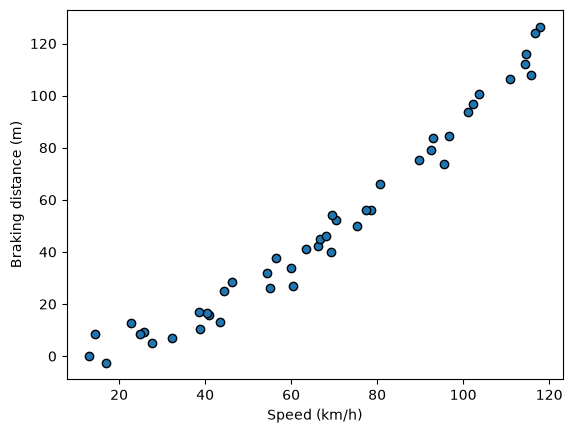

In [12]:
rng = np.random.default_rng(1)
n = 45
speed = rng.uniform(10, 120, n)                                      # km/h
distance = 0.0075 * speed**2 + 0.15 * speed + rng.normal(0, 6, n)    # metres

plt.scatter(speed, distance, edgecolor="k")
plt.xlabel("Speed (km/h)")
plt.ylabel("Braking distance (m)")
plt.show()

To judge models fairly we keep some points **aside** (validation set) and fit only on the rest (training set).

In [13]:
perm = np.random.default_rng(0).permutation(n)
train, val = perm[:25], perm[25:]
x_train, y_train = speed[train].reshape(-1, 1), distance[train]
x_val, y_val = speed[val].reshape(-1, 1), distance[val]

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

## 2.2 The straight line fails

The residuals (data minus line) should look like random noise around 0. Do they?

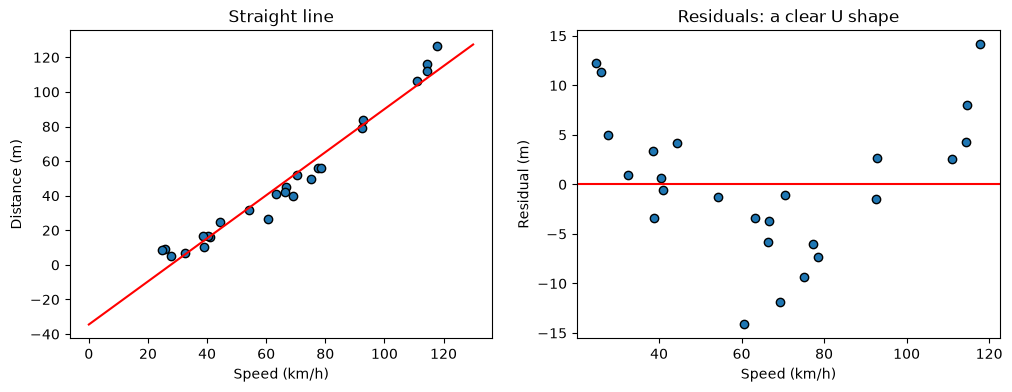

In [14]:
line = LinearRegression().fit(x_train, y_train)
xs = np.linspace(0, 130, 200).reshape(-1, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(x_train, y_train, edgecolor="k")
ax[0].plot(xs, line.predict(xs), color="red")
ax[0].set(xlabel="Speed (km/h)", ylabel="Distance (m)", title="Straight line")
ax[1].scatter(x_train, y_train - line.predict(x_train), edgecolor="k")
ax[1].axhline(0, color="red")
ax[1].set(xlabel="Speed (km/h)", ylabel="Residual (m)", title="Residuals: a clear U shape")
plt.show()

The U-shaped residuals mean the model is **too simple** (*underfitting*): there is a pattern it does not capture.

## 2.3 Adding the column $x^2$

`PolynomialFeatures(degree)` creates the columns $x, x^2, \dots, x^d$ for us. We first standardise $x$ with `StandardScaler` (powers of 100 km/h, or of the year 2005, would be gigantic numbers and the fit would become numerically unstable). We chain the steps with `make_pipeline`:

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def poly_model(degree):
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(degree, include_bias=False),
                         LinearRegression())

quad = poly_model(2).fit(x_train, y_train)
print("train RMSE:", round(rmse(y_train, quad.predict(x_train)), 2), "m")
print("val   RMSE:", round(rmse(y_val, quad.predict(x_val)), 2), "m")

train RMSE: 3.6 m
val   RMSE: 5.56 m


## 2.4 Which degree?

More degrees = more flexibility. Let's try 1, 2, 3, 6 and 10. **Blue** = training points (used to fit), **orange** = validation points (never seen).

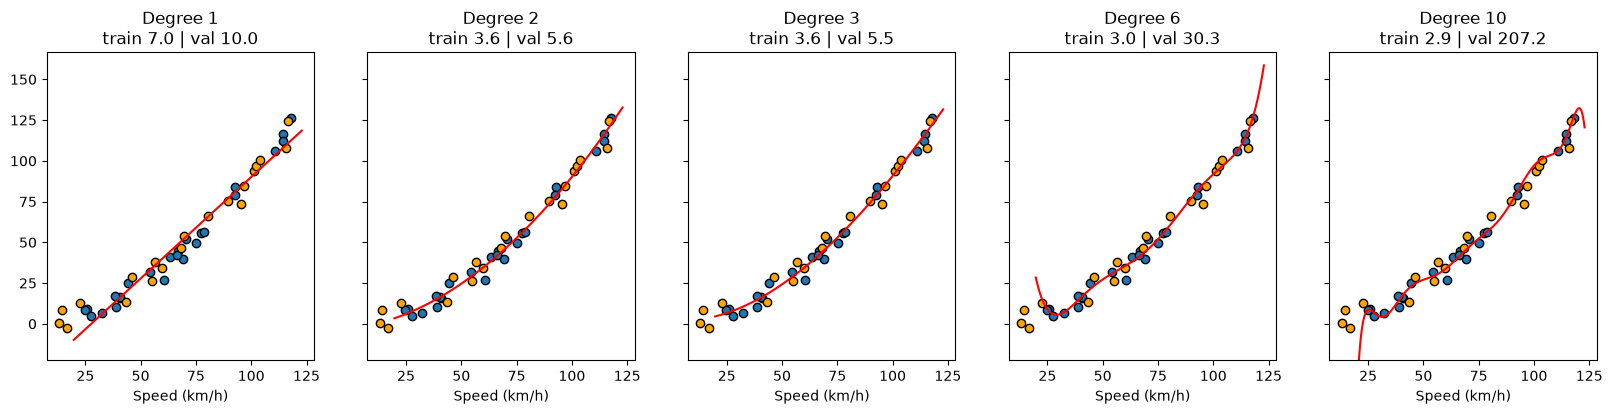

In [16]:
degrees = [1, 2, 3, 6, 10]
xs = np.linspace(x_train.min() - 5, x_train.max() + 5, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, len(degrees), sharey=True, figsize=(20, 4))
for d, ax in zip(degrees, axes):
    model = poly_model(d).fit(x_train, y_train)
    ax.scatter(x_train, y_train, edgecolor="k")
    ax.scatter(x_val, y_val, edgecolor="k", color="orange")
    ax.plot(xs, model.predict(xs), color="red")
    ax.set_ylim(distance.min() - 20, distance.max() + 40)
    ax.set_title(f"Degree {d}\ntrain {rmse(y_train, model.predict(x_train)):.1f} | "
                 f"val {rmse(y_val, model.predict(x_val)):.1f}")
    ax.set_xlabel("Speed (km/h)")
plt.show()

* **Degree 1**: too rigid, high error everywhere (*underfitting*).
* **Degrees 2-3**: follow the trend, low error in train *and* validation.
* **Degrees 6-10**: nearly perfect on the training points, but they wiggle between them and the validation error explodes (*overfitting*: the model memorised the noise).

The training error can only go down as the degree grows, so **we choose the degree with the validation error**:

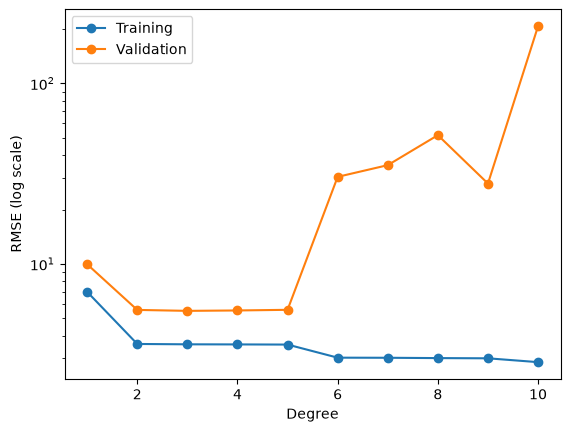

Best degree on validation: 3


In [17]:
degrees = range(1, 11)
tr = [rmse(y_train, poly_model(d).fit(x_train, y_train).predict(x_train)) for d in degrees]
va = [rmse(y_val,   poly_model(d).fit(x_train, y_train).predict(x_val))   for d in degrees]

plt.semilogy(degrees, tr, "o-", label="Training")
plt.semilogy(degrees, va, "o-", label="Validation")
plt.xlabel("Degree"); plt.ylabel("RMSE (log scale)"); plt.legend(); plt.show()
print("Best degree on validation:", list(degrees)[int(np.argmin(va))])

## 2.5 Making a prediction... and the danger of extrapolating

Within the range of the data (10-120 km/h) the good models agree. What do they say for a car at **150 km/h**, outside the data? (The true value is about 190 m.)

In [18]:
for d in [1, 2, 3, 10]:
    pred = poly_model(d).fit(x_train, y_train).predict([[150.0]])[0]
    print(f"degree {d:2d}: braking distance at 150 km/h = {pred:12.1f} m")

degree  1: braking distance at 150 km/h =        152.3 m
degree  2: braking distance at 150 km/h =        193.4 m
degree  3: braking distance at 150 km/h =        185.8 m
degree 10: braking distance at 150 km/h =     -45058.1 m


The line underestimates, degrees 2-3 get close, and degree 10 predicts an absurd number. **Outside the range of the data, high-degree polynomials explode.** Predict only inside the range you trained on.

## ✏️ Exercise 2 (10 min): the economy of Cuba

Cuba's PPP (purchasing power parity, in US dollars) from 1999 to 2010. Note that there is no 2001.

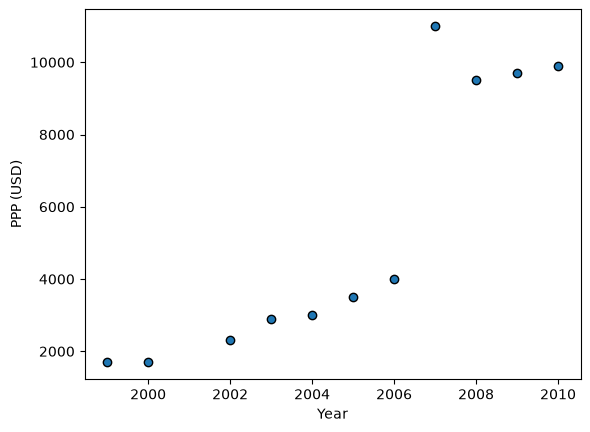

In [19]:
cuba = pd.read_csv(BASE + "cuba_ppp.csv")
plt.scatter(cuba["year"], cuba["ppp_usd"], edgecolor="k")
plt.xlabel("Year"); plt.ylabel("PPP (USD)"); plt.show()

1. Fit polynomials of degree 1, 2 and 3 with `poly_model(d)` (the input must be a 2D column: `cuba[["year"]]`).
2. Plot the three curves over the data (use years from 1999 to 2014 for the curve).
3. **Predict the PPP for 2014** with each degree. Do the three agree?
4. Which model would you trust, and why? (Think of the 2007 jump, the number of points, and what happens outside the data.)
5. *(if you have time)* Compare the $R^2$ of the three models. Does a higher $R^2$ mean a better prediction here?

degree 1: R2 = 0.774 | PPP in 2014 = 13,822
degree 2: R2 = 0.821 | PPP in 2014 = 19,309
degree 3: R2 = 0.857 | PPP in 2014 = 4,759


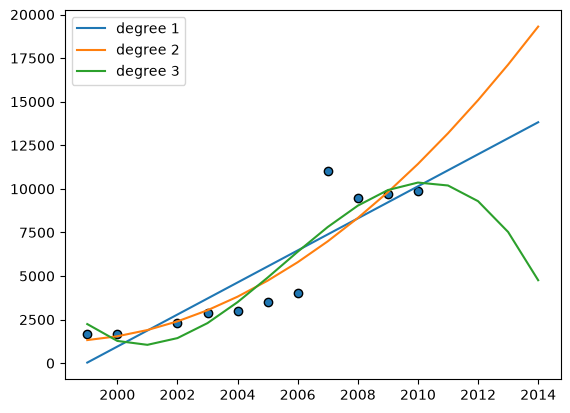

In [20]:
X_c, y_c = cuba[["year"]], cuba["ppp_usd"]
years = pd.DataFrame({"year": np.arange(1999, 2015)})

plt.scatter(cuba["year"], y_c, edgecolor="k")
for d in [1, 2, 3]:
    m = poly_model(d).fit(X_c, y_c)
    plt.plot(years["year"], m.predict(years), label=f"degree {d}")
    print(f"degree {d}: R2 = {r2_score(y_c, m.predict(X_c)):.3f} | PPP in 2014 = {m.predict(pd.DataFrame({'year': [2014]}))[0]:,.0f}")
plt.legend(); plt.show()

---
*Your answer to 4 here*

---

# Summary

| | Multiple regression | Polynomial regression |
|---|---|---|
| Idea | several columns $x_1, \dots, x_k$ | extra columns $x^2, \dots, x^d$ built from one variable |
| Fit | least squares / gradient descent | the same |
| Watch out | useless variables still raise $R^2$: check **p-values** and adjusted $R^2$ | too high a degree **overfits**; never extrapolate |
| How to choose | compare on data not used to fit | validation error |

**Next session:** classifying with *logistic regression* and **regularization**, the tool that keeps a high-degree model from overfitting.